# 03 · Análisis exploratorio y visualizaciones estáticas
**StreamView Analytics · ADY1104 EP3** — cubre **IE13** (visualizaciones estáticas con librerías especializadas) y las secciones del informe *Análisis exploratorio* y *Justificación de las representaciones gráficas*.

Lee las tablas de `data/processed/looker/` (generadas en el notebook 02) y guarda cada gráfico en `images/` para reutilizarlo en el informe y el resumen ejecutivo.
Cada gráfico tiene: **pregunta de negocio → representación elegida y por qué → hallazgo**.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, matplotlib.ticker as mt, squarify
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'data/processed/looker/catalogo_looker.csv').is_file())
L = ROOT/'data/processed/looker'; IMG = ROOT/'images'; IMG.mkdir(exist_ok=True)
cat  = pd.read_csv(L/'catalogo_looker.csv'); gen = pd.read_csv(L/'generos_long.csv'); pai = pd.read_csv(L/'paises_long.csv')
dire = pd.read_csv(L/'directores_long.csv'); act = pd.read_csv(L/'actores_long.csv')

# Paleta accesible (apta daltonismo) y consistente en todo el proyecto: Movie = azul, TV Show = naranja
AZUL, NARANJA, GRIS, VERDE = '#1F5FA8', '#E07B39', '#8A8F98', '#2A9D8F'
COL = {'Movie':AZUL, 'TV Show':NARANJA}
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.25,'axes.axisbelow':True,
                     'font.size':10,'axes.titlesize':12,'axes.titleweight':'bold','axes.titlelocation':'left'})
ALCANCE = 'Extracto StreamView 2010–2025'
def guardar(fig, nombre): fig.tight_layout(); fig.savefig(IMG/f'{nombre}.png', dpi=160, bbox_inches='tight'); plt.show()
print(cat.shape)

(32000, 31)


## 1. Catálogo: ¿qué géneros predominan?
**Representación:** barras horizontales agrupadas por tipo. Comparar **longitudes alineadas** es la tarea de percepción más precisa; las categorías tienen nombres largos, por eso horizontal y ordenadas de mayor a menor. Color = tipo (Movie/TV Show), consistente en todo el proyecto.
Se usan **todas las etiquetas de género** (tabla long), no solo la principal.

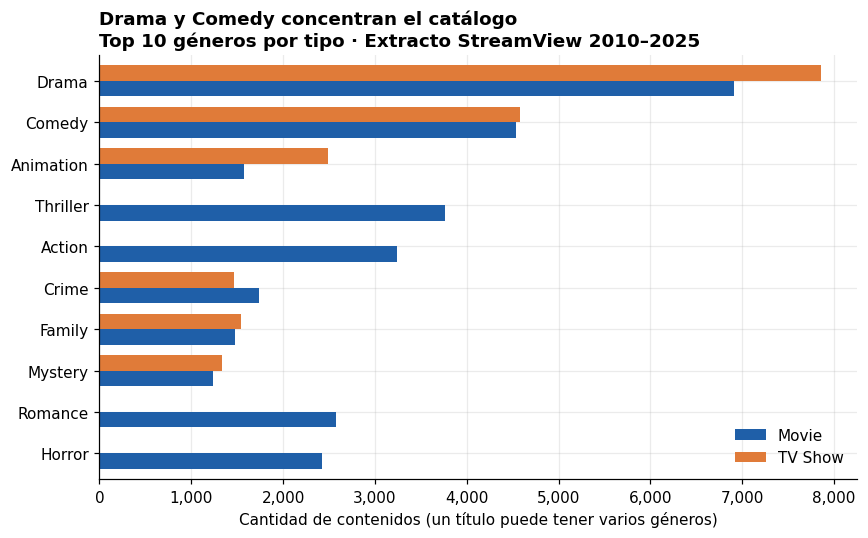

In [2]:
top = gen.genero.value_counts().head(10).index
t = gen[gen.genero.isin(top)].groupby(['genero','type']).size().unstack(fill_value=0).loc[top[::-1]]
fig, ax = plt.subplots(figsize=(8,5)); t.plot.barh(ax=ax, color=[COL[c] for c in t.columns], width=.75)
ax.set_title(f'Drama y Comedy concentran el catálogo\nTop 10 géneros por tipo · {ALCANCE}'); ax.set_xlabel('Cantidad de contenidos (un título puede tener varios géneros)'); ax.set_ylabel('')
ax.xaxis.set_major_formatter(mt.StrMethodFormatter('{x:,.0f}')); ax.legend(title='', frameon=False); guardar(fig,'eda_01_generos_por_tipo')

## 2. Catálogo: composición por género (treemap)
**Representación:** treemap (requerido por el caso). Muestra la **parte-todo** y la jerarquía de tamaños de muchas categorías a la vez, donde un gráfico de torta no sería legible. Se usa `genero_principal` (una categoría por título) para que las áreas sumen el 100 %.

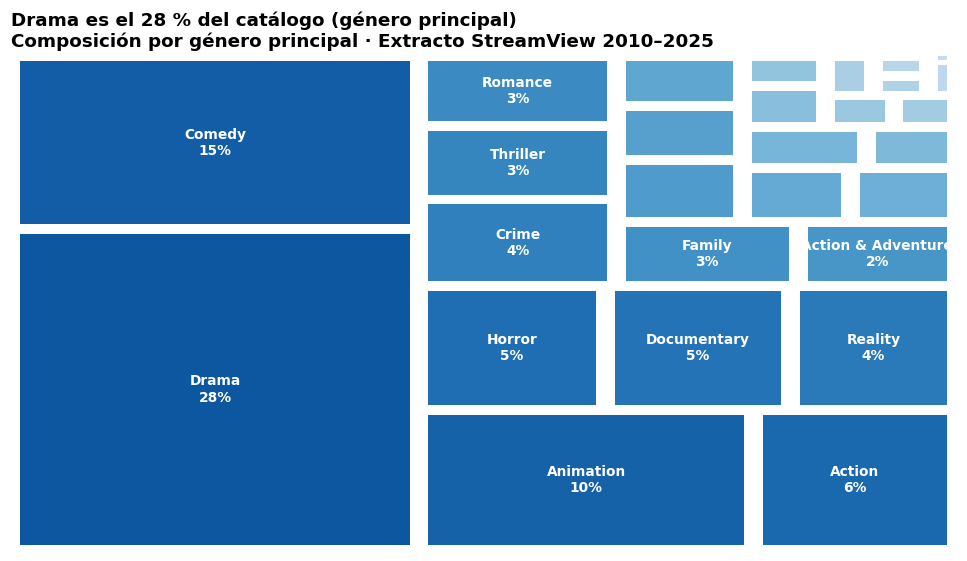

In [3]:
g = cat.genero_principal.value_counts(); g = g[g.index!='Sin dato']
fig, ax = plt.subplots(figsize=(9,5.2))
cmap = plt.cm.Blues(np.linspace(.85,.25,len(g)))
squarify.plot(sizes=g.values, label=[f'{k}\n{v/g.sum():.0%}' if v/g.sum()>.02 else '' for k,v in g.items()], color=cmap, pad=True, ax=ax, text_kwargs={'color':'white','fontsize':9,'fontweight':'bold'})
ax.axis('off'); ax.set_title(f'Drama es el 28 % del catálogo (género principal)\nComposición por género principal · {ALCANCE}'); guardar(fig,'eda_02_treemap_generos')

## 3. Catálogo: países e idiomas
**Representación:** barras horizontales ordenadas (ranking). Para geografía el dashboard usará además un **mapa coroplético** en Looker Studio; aquí el ranking permite leer valores exactos.
Países: tabla long (cuenta co-producciones en cada país participante).

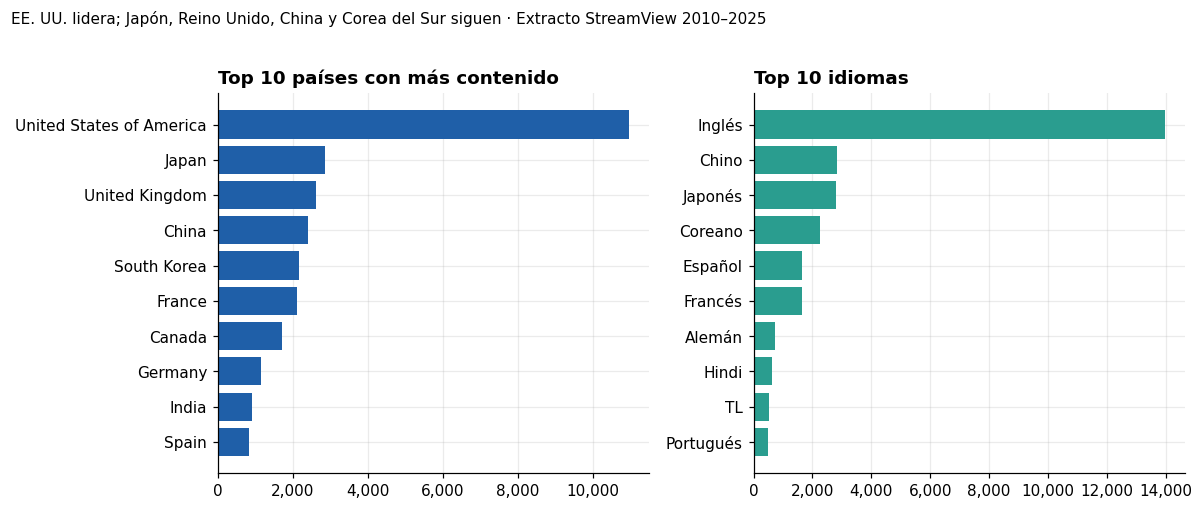

In [4]:
fig, axs = plt.subplots(1,2, figsize=(11,4.5))
p = pai.pais.value_counts().head(10)[::-1]; axs[0].barh(p.index, p.values, color=AZUL); axs[0].set_title('Top 10 países con más contenido'); axs[0].xaxis.set_major_formatter(mt.StrMethodFormatter('{x:,.0f}'))
i = cat.idioma.value_counts().head(10)[::-1]; axs[1].barh(i.index, i.values, color=VERDE); axs[1].set_title('Top 10 idiomas'); axs[1].xaxis.set_major_formatter(mt.StrMethodFormatter('{x:,.0f}'))
fig.suptitle(f'EE. UU. lidera; Japón, Reino Unido, China y Corea del Sur siguen · {ALCANCE}', x=.01, ha='left', fontsize=10, y=1.02); guardar(fig,'eda_03_paises_idiomas')

## 4. Popularidad y valoración por género
**Pregunta:** ¿qué géneros concentran el mayor interés y mejor evaluación? **Representación:** barras de la **mediana** de popularidad (la popularidad es muy asimétrica; el promedio lo dominan pocos títulos) con la nota promedio anotada.
Se restringe a géneros con ≥ 300 títulos para evitar conclusiones con poca muestra.

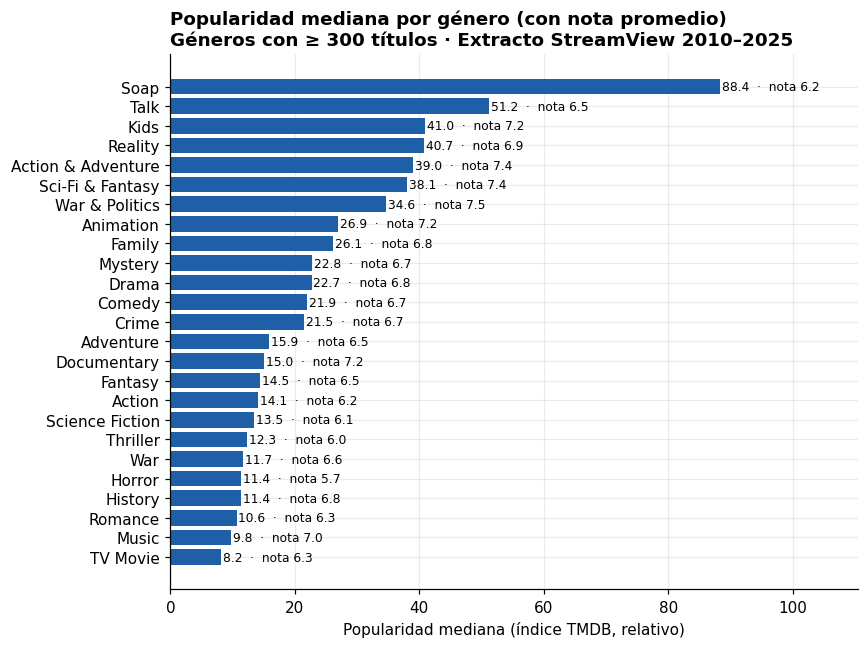

                       n  pop_med  nota
genero                                 
Soap                 631    88.40  6.25
Talk                 655    51.20  6.45
Kids                 835    40.97  7.20
Reality             1631    40.74  6.86
Action & Adventure  1988    39.00  7.40


In [5]:
r = gen.groupby('genero').agg(n=('content_key','size'), pop_med=('popularity','median'), nota=('vote_average_valida','mean')).query('n>=300').sort_values('pop_med')
fig, ax = plt.subplots(figsize=(8,6)); b = ax.barh(r.index, r.pop_med, color=AZUL)
for y,(v,nota) in enumerate(zip(r.pop_med, r.nota)): ax.text(v+.3, y, f'{v:.1f}  ·  nota {nota:.1f}', va='center', fontsize=8)
ax.set_xlim(0, r.pop_med.max()*1.25); ax.set_xlabel('Popularidad mediana (índice TMDB, relativo)')
ax.set_title(f'Popularidad mediana por género (con nota promedio)\nGéneros con ≥ 300 títulos · {ALCANCE}'); guardar(fig,'eda_04_popularidad_por_genero')
print(r.sort_values('pop_med',ascending=False).round(2).head(5))

## 5. Valoración: ¿existe relación entre popularidad y calificación?
**Representación:** diagrama de **dispersión** (dos variables numéricas → relación). Popularidad en escala **logarítmica** porque su distribución es muy asimétrica (mediana ≈ 22, máximo > 6.000). Solo títulos con ≥ 50 votos, para que la nota sea confiable. Las líneas de mediana definen los cuadrantes que se reutilizan en el dashboard.

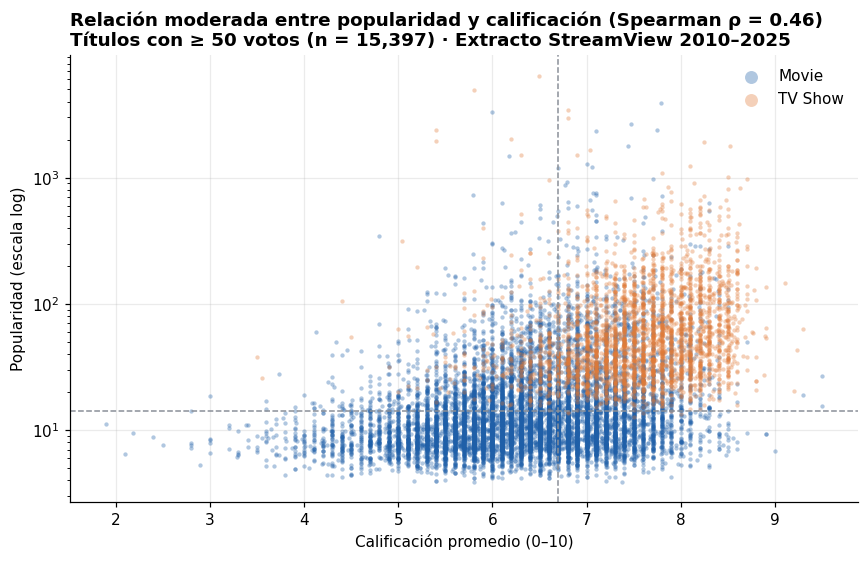

In [6]:
b = cat[cat.ranking_confiable.eq('Sí')]
rho = b[['popularity','vote_average_valida']].corr(method='spearman').iloc[0,1]
fig, ax = plt.subplots(figsize=(8,5.2))
for k,c in COL.items(): s=b[b.type==k]; ax.scatter(s.vote_average_valida, s.popularity, s=8, alpha=.35, color=c, label=k, linewidths=0)
ax.set_yscale('log'); ax.axhline(b.popularity.median(), color=GRIS, ls='--', lw=1); ax.axvline(b.vote_average_valida.median(), color=GRIS, ls='--', lw=1)
ax.set_xlabel('Calificación promedio (0–10)'); ax.set_ylabel('Popularidad (escala log)'); ax.legend(frameon=False, markerscale=3)
ax.set_title(f'Relación moderada entre popularidad y calificación (Spearman ρ = {rho:.2f})\nTítulos con ≥ 50 votos (n = {len(b):,}) · {ALCANCE}'); guardar(fig,'eda_05_dispersion_popularidad_calificacion')

## 6. Películas vs series: valoración a lo largo del tiempo
**Pregunta:** ¿existen diferencias entre películas y series? **Representación:** líneas (serie temporal, 16 puntos por tipo). Se usa la nota promedio con votos por año de estreno. Regla 7: el alcance (2010–2025, 2.000 títulos por año) se indica en el subtítulo.

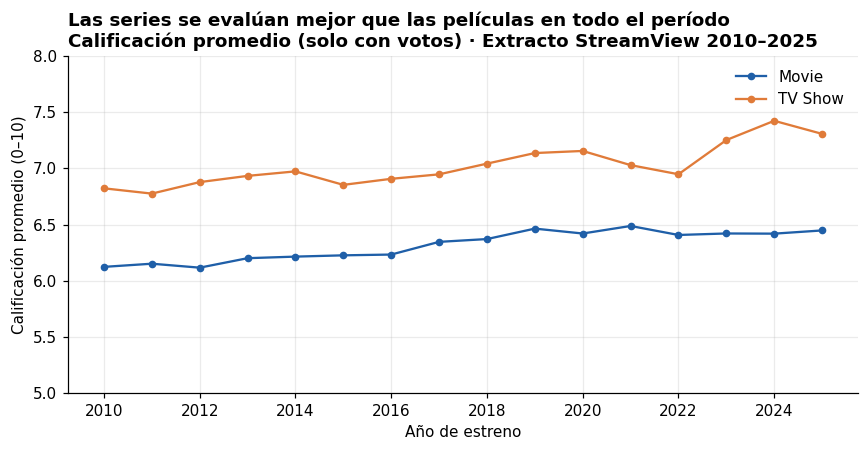

type
Movie      6.31
TV Show    7.02
Name: vote_average_valida, dtype: float64


In [7]:
t = cat[cat.calificado.eq('Sí')].groupby(['release_year','type']).vote_average_valida.mean().unstack()
fig, ax = plt.subplots(figsize=(8,4.2))
for k in t: ax.plot(t.index, t[k], marker='o', ms=4, color=COL[k], label=k)
ax.set_ylim(5, 8); ax.set_xlabel('Año de estreno'); ax.set_ylabel('Calificación promedio (0–10)'); ax.legend(frameon=False)
ax.set_title(f'Las series se evalúan mejor que las películas en todo el período\nCalificación promedio (solo con votos) · {ALCANCE}'); guardar(fig,'eda_06_calificacion_por_anio')
print(cat[cat.calificado=='Sí'].groupby('type').vote_average_valida.mean().round(2))

## 7. Finanzas (solo películas): presupuesto vs ingresos
**Pregunta:** ¿existe relación entre presupuesto e ingresos? **Representación:** dispersión en escala log-log (ambos ejes abarcan varios órdenes de magnitud). La diagonal ROI = 1 separa las películas que recuperaron su inversión (arriba) de las que no. Solo películas con datos válidos (regla 6).

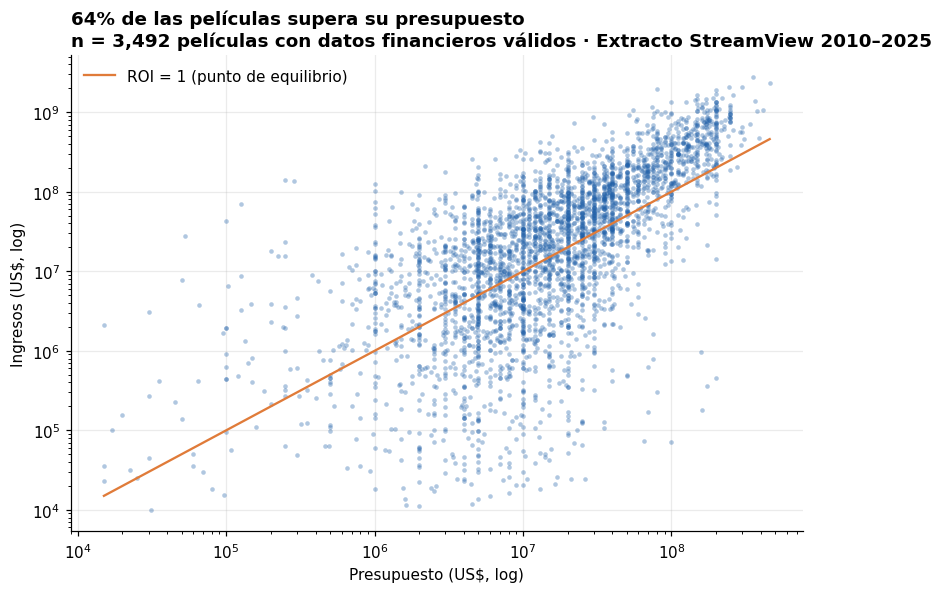

In [8]:
f = cat[cat.tiene_datos_financieros.eq('Sí')]
fig, ax = plt.subplots(figsize=(7.5,5.5)); ax.scatter(f.budget_valido, f.revenue_valido, s=9, alpha=.35, color=AZUL, linewidths=0)
lim = [f.budget_valido.min(), f.budget_valido.max()]; ax.plot(lim, lim, color=NARANJA, lw=1.5, label='ROI = 1 (punto de equilibrio)')
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlabel('Presupuesto (US$, log)'); ax.set_ylabel('Ingresos (US$, log)'); ax.legend(frameon=False)
pct = (f.roi>=1).mean()
ax.set_title(f'{pct:.0%} de las películas supera su presupuesto\nn = {len(f):,} películas con datos financieros válidos · {ALCANCE}'); guardar(fig,'eda_07_presupuesto_vs_ingresos')

## 8. Finanzas: ¿qué películas fueron exitosas con presupuestos reducidos?
**Representación:** barras del **ROI mediano** por rango de presupuesto (mediana, no promedio: el ROI tiene cola larga). Se anota el n de cada rango para no sobre-interpretar los grupos pequeños.

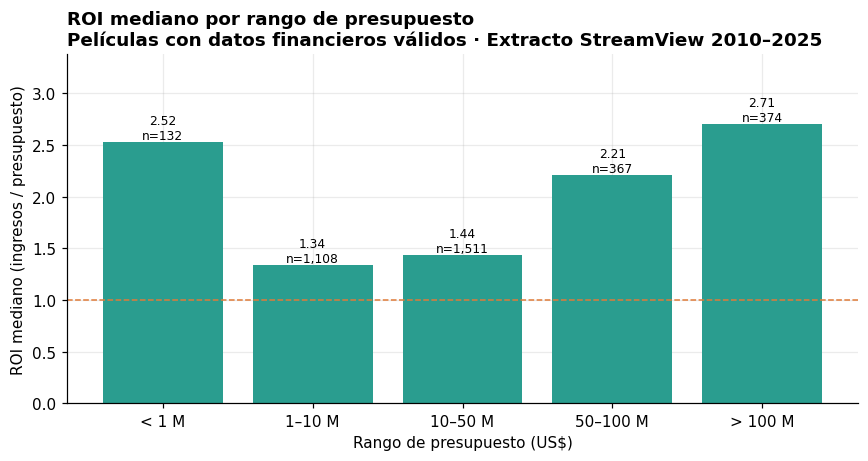

,roi_med,n,pct_rentables
rango_presupuesto,,,
1) < 1 M,2.52,132,0.73
2) 1–10 M,1.34,1108,0.57
3) 10–50 M,1.44,1511,0.59
4) 50–100 M,2.21,367,0.78
5) > 100 M,2.71,374,0.87


In [9]:
r = f.groupby('rango_presupuesto').agg(roi_med=('roi','median'), n=('content_key','size'), pct_rentables=('roi', lambda s:(s>=1).mean()))
fig, ax = plt.subplots(figsize=(8,4.3)); ax.bar(r.index.str[3:], r.roi_med, color=VERDE)
for x,(v,n) in enumerate(zip(r.roi_med, r.n)): ax.text(x, v+.03, f'{v:.2f}\nn={n:,}', ha='center', fontsize=8)
ax.axhline(1, color=NARANJA, ls='--', lw=1); ax.set_ylim(0, r.roi_med.max()*1.25); ax.set_xlabel('Rango de presupuesto (US$)'); ax.set_ylabel('ROI mediano (ingresos / presupuesto)')
ax.set_title(f'ROI mediano por rango de presupuesto\nPelículas con datos financieros válidos · {ALCANCE}'); guardar(fig,'eda_08_roi_por_presupuesto')
r.round(2)

In [10]:
# Películas exitosas con presupuesto reducido (candidatas a caso de estudio)
f[f.exito_bajo_presupuesto.eq('Sí')].nlargest(10,'roi')[['title','release_year','budget_valido','revenue_valido','roi']].round(1)

,title,release_year,budget_valido,revenue_valido,roi
8803,Animal World,2018,125000.0,69885700.0,559.1
5339,Mr. Six,2015,250000.0,139191345.0,556.8
7238,One Cut of the Dead,2017,52406.0,27590180.0,526.5
7739,Secret Superstar,2017,286284.0,137416709.0,480.0
5365,The Gallows,2015,100000.0,42964410.0,429.6
13433,Winnie the Pooh: Blood and Honey,2023,50000.0,7717044.0,154.3
13380,Skinamarink,2023,15000.0,2100000.0,140.0
8732,Dragon Ball Super: Broly,2018,1000000.0,125002821.0,125.0
2230,The Devil Inside,2012,1000000.0,101800000.0,101.8
491,Catfish,2010,30000.0,3045943.0,101.5


## 9. Producción: directores y actores con mayor presencia
**Representación:** barras horizontales (ranking de frecuencia). Sin `No especificado`: los directores nulos (11.097 títulos, sobre todo series) no entran al ranking, y eso se indica en el gráfico.

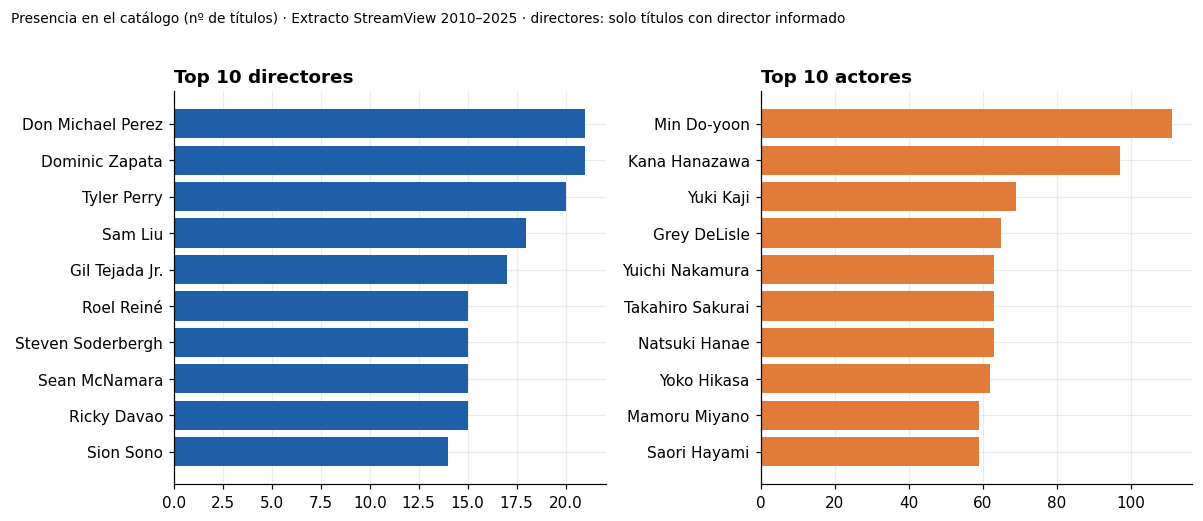

In [11]:
fig, axs = plt.subplots(1,2, figsize=(11,4.6))
d = dire.director.value_counts().head(10)[::-1]; axs[0].barh(d.index, d.values, color=AZUL); axs[0].set_title('Top 10 directores')
a = act.actor.value_counts().head(10)[::-1];   axs[1].barh(a.index, a.values, color=NARANJA); axs[1].set_title('Top 10 actores')
fig.suptitle(f'Presencia en el catálogo (nº de títulos) · {ALCANCE} · directores: solo títulos con director informado', x=.01, ha='left', fontsize=9, y=1.02); guardar(fig,'eda_09_directores_actores')

## 10. Resumen de hallazgos (insumo del Data Storytelling)
Completar con las cifras impresas arriba y las de `data/processed/looker/cifras_de_control.csv`. Estructura sugerida por el caso (§23): **¿Qué ocurre? → ¿Por qué? → ¿Qué evidencia lo demuestra? → ¿Qué decisiones tomar?**

| Hallazgo | Evidencia (figura) | Decisión sugerida |
|---|---|---|
| Drama y Comedy dominan el catálogo | `eda_01`, `eda_02` | Priorizar diversificación vs. profundizar en géneros dominantes |
| Popularidad y nota se relacionan solo de forma moderada (ρ ≈ 0,46) | `eda_05` | No usar popularidad como sustituto de calidad al adquirir |
| Las series se valoran mejor que las películas | `eda_06` | Reforzar adquisición/promoción de series |
| ~36 % de las películas no recupera su presupuesto; los rangos 1–50 M tienen el ROI mediano más bajo | `eda_07`, `eda_08` | Ser selectivo en presupuestos medios; los de bajo costo pueden ser muy rentables |
| Latinoamérica tiene poca presencia (≈ 4 % de los títulos por país principal; español ≈ 5 % por idioma) pese a ser el mercado objetivo | `eda_03` + filtro de país en el dashboard | Oportunidad de adquisición regional |